In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py
import re

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/refining/data_slash_results/"
filename = root + 'archs4_gene_human_v2.1_normalized_LW20230126.h5'
with h5py.File(filename, 'r') as f:
    qn_matrix = f['data/qn_matrix'][:]
    gene_names = f['meta/genes/all_gene_names'][:]
    category_names = f['meta/biosamples/category'][:]

category_names = [x.decode('UTF-8') for x in category_names]
gene_names = [x.decode('UTF-8') for x in gene_names]

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py
import re

In [ ]:
root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/refining/data_slash_results/"
filename = root + 'archs4_gene_human_v2.1_normalized_LW20230126.h5'
with h5py.File(filename, 'r') as f:
    extracted_matrix = f['data/raw_matrix'][:]

# plot original matrix across rows

# Calculate the row sums
row_sums = extracted_matrix.sum(axis=1)

# Convert row_sums to integer values
row_sums = row_sums.astype(int)

# Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(row_sums, bins=range(0, row_sums.max()+1))
plt.ylim(0,10)

plt.title('Raw matrix across genes')
plt.xlabel('Raw gene expression sums')
plt.ylabel('Frequency')

#plt.xticks(np.arange(0, row_sums.max()+1, 1000), np.arange(0, row_sums.max()+1, 1000))

In [5]:
row_totals = np.sum(qn_matrix, axis=1)
col_totals = np.sum(qn_matrix, axis=0)
total = np.sum(qn_matrix)
expected = np.outer(row_totals, col_totals) / total
print("**Expected Matrix**")
print(expected.shape)
print()

observed = qn_matrix
normalized = observed / expected 
print("**Normalized Matrix**")
print(normalized.shape)

**Expected Matrix**
(57447, 87875)

**Normalized Matrix**
(57447, 87875)


In [6]:
pos_log_normalized = np.log2(normalized + 1)
print("**Positive Log-Normalized Matrix**")
print(pos_log_normalized.shape)

**Positive Log-Normalized Matrix**
(57447, 87875)


Text(0, 0.5, 'Frequency')

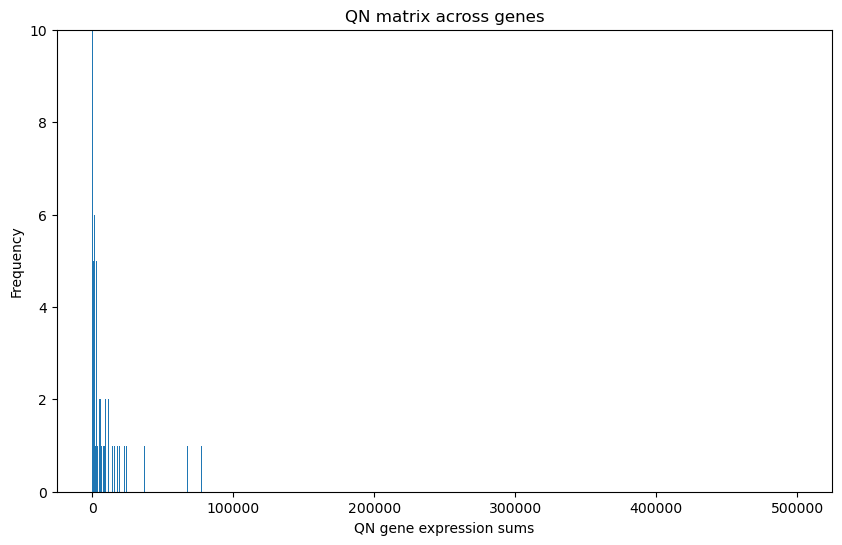

In [20]:
# plot qn matrix across rows

# Calculate the row sums
row_sums = qn_matrix.sum(axis=1)

# Convert row_sums to integer values
row_sums = row_sums.astype(int)

# Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(row_sums, bins=range(0, row_sums.max()+1))
plt.ylim(0,10)

plt.title('QN matrix across genes')
plt.xlabel('QN gene expression sums')
plt.ylabel('Frequency')

#plt.xticks(np.arange(0, row_sums.max()+1, 1000), np.arange(0, row_sums.max()+1, 1000))

In [11]:
max(row_sums)

499519

Text(0, 0.5, 'Frequency')

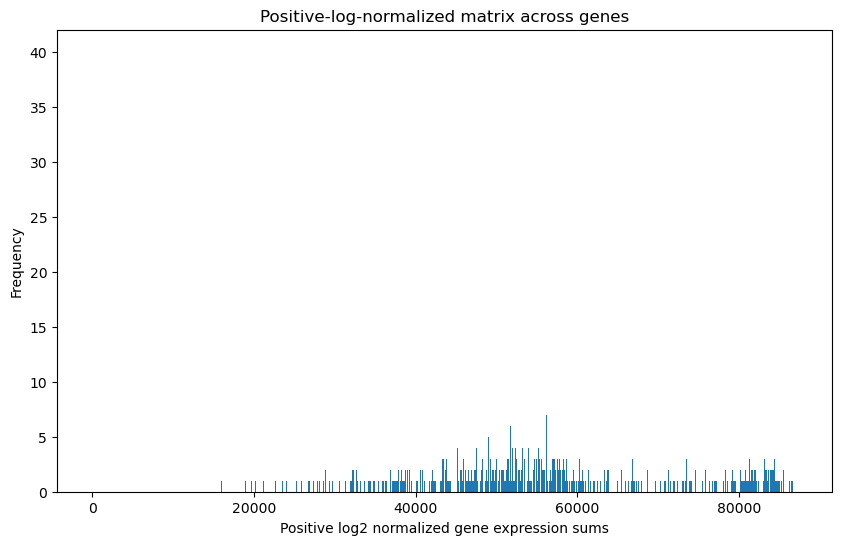

In [14]:
# Calculate the row sums
row_sums = pos_log_normalized.sum(axis=1)

# Convert row_sums to integer values
row_sums = row_sums.astype(int)

# Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(row_sums, bins=range(0, row_sums.max()+1))

plt.title('Positive-log-normalized matrix across genes')
plt.xlabel('Positive log2 normalized gene expression sums')
plt.ylabel('Frequency')


Text(0, 0.5, 'Frequency')

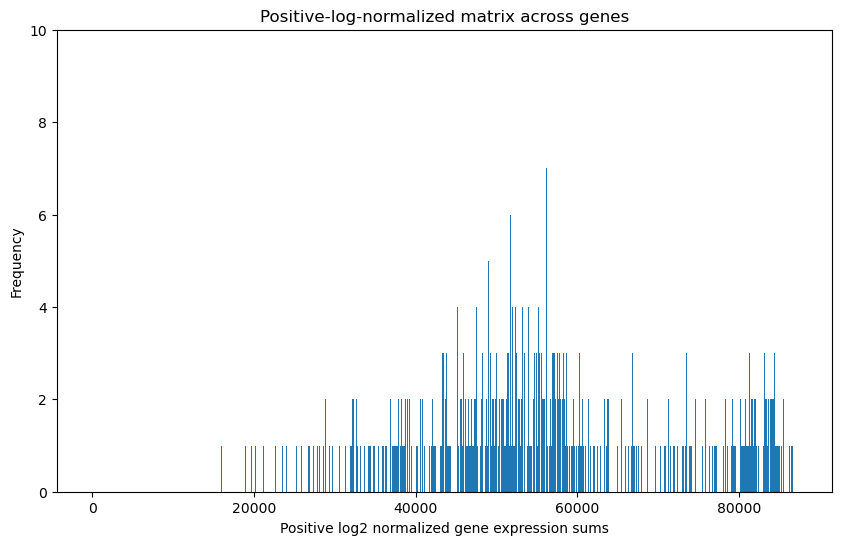

In [16]:
# Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(row_sums, bins=range(0, row_sums.max()+1))
plt.ylim(0,10)
plt.title('Positive-log-normalized matrix across genes')
plt.xlabel('Positive log2 normalized gene expression sums')
plt.ylabel('Frequency')


In [13]:
file = h5py.File(filename, "a")

# write the list to the dataset in the pathway "meta/biosamples/"
file["data/logOE_matrix"] = pos_log_normalized

# close the h5py file
file.close()

---